In [75]:
# Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
import joblib

In [60]:
# Load the insider threat dataset into pandas DataFrames
logon = pd.read_csv("logon.csv")
device = pd.read_csv("device.csv")
file = pd.read_csv("file.csv")

In [61]:
# Display the first few records and column names of the logon dataset
print(logon.shape)
print(logon.columns)
logon.head()

(854859, 5)
Index(['id', 'date', 'user', 'pc', 'activity'], dtype='str')


,id,date,user,pc,activity
0,{X1D9-S0ES98JV-5357PWMI},01/02/2010 06:49:00,NGF0157,PC-6056,Logon
1,{G2B3-L6EJ61GT-2222RKSO},01/02/2010 06:50:00,LRR0148,PC-4275,Logon
2,{U6Q3-U0WE70UA-3770UREL},01/02/2010 06:53:04,LRR0148,PC-4124,Logon
3,{I0N5-R7NA26TG-6263KNGM},01/02/2010 07:00:00,IRM0931,PC-7188,Logon
4,{D1S0-N6FH62BT-5398KANK},01/02/2010 07:00:00,MOH0273,PC-6699,Logon


In [62]:
# Display the first few records and column names of the device dataset
print(device.shape)
print(device.columns)
device.head()

(405380, 5)
Index(['id', 'date', 'user', 'pc', 'activity'], dtype='str')


,id,date,user,pc,activity
0,{J1S3-L9UU75BQ-7790ATPL},01/02/2010 07:21:06,MOH0273,PC-6699,Connect
1,{N7B5-Y7BB27SI-2946PUJK},01/02/2010 07:37:41,MOH0273,PC-6699,Disconnect
2,{U1V9-Z7XT67KV-5649MYHI},01/02/2010 07:59:11,HPH0075,PC-2417,Connect
3,{H0Z7-E6GB57XZ-1603MOXD},01/02/2010 07:59:49,IIW0249,PC-0843,Connect
4,{L7P2-G4PX02RX-7999GYOY},01/02/2010 08:04:26,IIW0249,PC-0843,Disconnect


In [63]:
# Display the first few records and column names of the file dataset
print(file.shape)
print(file.columns)
file.head()

(445581, 6)
Index(['id', 'date', 'user', 'pc', 'filename', 'content'], dtype='str')


,id,date,user,pc,filename,content
0,{L9G8-J9QE34VM-2834VDPB},01/02/2010 07:23:14,MOH0273,PC-6699,EYPC9Y08.doc,D0-CF-11-E0-A1-B1-1A-E1 during difficulty over...
1,{H0W6-L4FG38XG-9897XTEN},01/02/2010 07:26:19,MOH0273,PC-6699,N3LTSU3O.pdf,25-50-44-46-2D carpenters 25 landed strait dis...
2,{M3Z0-O2KK89OX-5716MBIM},01/02/2010 08:12:03,HPH0075,PC-2417,D3D3WC9W.doc,D0-CF-11-E0-A1-B1-1A-E1 union 24 declined impo...
3,{E1I4-S4QS61TG-3652YHKR},01/02/2010 08:17:00,HPH0075,PC-2417,QCSW62YS.doc,D0-CF-11-E0-A1-B1-1A-E1 becoming period begin ...
4,{D4R7-E7JL45UX-0067XALT},01/02/2010 08:24:57,HSB0196,PC-8001,AU75JV6U.jpg,FF-D8


Data Quality

In [64]:
# check data quality by identifying missing values and duplicate records
print(logon.isnull().sum())
print(logon.duplicated().sum())

print(device.isnull().sum())
print(device.duplicated().sum())

print(file.isnull().sum())
print(file.duplicated().sum())


id          0
date        0
user        0
pc          0
activity    0
dtype: int64
0
id          0
date        0
user        0
pc          0
activity    0
dtype: int64
0
id          0
date        0
user        0
pc          0
filename    0
content     0
dtype: int64
0


In [65]:
# Convert data columns to datatime format
logon['date'] = pd.to_datetime(logon['date'])
device['date'] = pd.to_datetime(device['date'])
file['date'] = pd.to_datetime(file['date'])
logon.info()

<class 'pandas.DataFrame'>
RangeIndex: 854859 entries, 0 to 854858
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   id        854859 non-null  str           
 1   date      854859 non-null  datetime64[us]
 2   user      854859 non-null  str           
 3   pc        854859 non-null  str           
 4   activity  854859 non-null  str           
dtypes: datetime64[us](1), str(4)
memory usage: 68.0 MB


In [66]:
#Extract the hour from each activity timestamp
logon['hour'] = logon['date'].dt.hour
device['hour'] = device['date'].dt.hour
file['hour'] = file['date'].dt.hour
logon[['date', 'hour']].head()

,date,hour
0,2010-01-02 06:49:00,6
1,2010-01-02 06:50:00,6
2,2010-01-02 06:53:04,6
3,2010-01-02 07:00:00,7
4,2010-01-02 07:00:00,7


In [67]:
# Identify activities outside normal working hours
logon['after_hours'] = ((logon['hour'] < 8) | (logon['hour'] > 17)).astype(int)

device['after_hours'] = ((device['hour'] < 8) | (device['hour'] > 17)).astype(int)

file['after_hours'] = ((file['hour'] < 8) | (file['hour'] > 17)).astype(int)
logon[['hour', 'after_hours']].head()

,hour,after_hours
0,6,1
1,6,1
2,6,1
3,7,1
4,7,1


Feature Engineering

In [68]:
# Generate behavioral features for ecah user
logon_features = logon.groupby('user').agg(
    logon_count=('activity', 'count'),
    unique_pcs=('pc', 'nunique'),
    after_hours_logons=('after_hours', 'sum')
)

logon_features.head()

,logon_count,unique_pcs,after_hours_logons
user,,,
AAE0190,692,1,346
AAF0535,328,1,0
AAF0791,692,1,0
AAL0706,692,1,346
AAM0658,458,1,234


In [69]:
# Generate device activity features for ecah user
device_features = device.groupby('user').agg(
    device_events=('activity', 'count'),
    device_unique_pcs=('pc', 'nunique'),
    after_hours_device=('after_hours', 'sum')
)

device_features.head()

,device_events,device_unique_pcs,after_hours_device
user,,,
AAF0535,688,1,0
AAM0658,13,1,13
ABC0174,1276,1,56
AHD0848,299,1,48
AHM0410,782,1,7


In [70]:
# Generate file activity features for ecah user
file_features = file.groupby('user').agg(
    file_events=('filename', 'count'),
    unique_file=('filename', 'nunique'),
    after_hours_file=('after_hours', 'sum')
)

file_features.head()

,file_events,unique_file,after_hours_file
user,,,
AAF0535,357,357,0
AAM0658,31,31,31
ABC0174,589,589,26
AHD0848,199,199,30
AHM0410,2198,2198,3


In [71]:
# Marge all user behavioral features
user_features = logon_features.join(device_features, how='outer')
user_features = user_features.join(file_features, how='outer')

user_features = user_features.fillna(0)
user_features.head()


,logon_count,unique_pcs,after_hours_logons,device_events,device_unique_pcs,after_hours_device,file_events,unique_file,after_hours_file
user,,,,,,,,,
AAE0190,692,1,346,0.0,0.0,0.0,0.0,0.0,0.0
AAF0535,328,1,0,688.0,1.0,0.0,357.0,357.0,0.0
AAF0791,692,1,0,0.0,0.0,0.0,0.0,0.0,0.0
AAL0706,692,1,346,0.0,0.0,0.0,0.0,0.0,0.0
AAM0658,458,1,234,13.0,1.0,13.0,31.0,31.0,31.0


In [72]:
# Train an Isolation Forst model for anomaly detection
model = IsolationForest(contamination=0.03, random_state=42)

# Generate anomaly prediction
user_features['anomaly'] = model.fit_predict(user_features)

# Convert prediction to binary labels
user_features['anomaly'] = user_features['anomaly'].map(
    {-1: 1, 1: 0}
)

# Display anomaly counts
print(user_features['anomaly'].value_counts())

anomaly
0    970
1     30
Name: count, dtype: int64


In [73]:
# Display anomalous users
anomalous_users = user_features[user_features['anomaly'] == 1]

print(anomalous_users.head(10))

         logon_count  unique_pcs  after_hours_logons  device_events  \
user                                                                  
AJF0370         3267         661                1889         8502.0   
AVM0947          750          30                 385         5984.0   
BAL0044         3146         628                2181         2258.0   
BMG0917         1005           1                 388         5955.0   
BRM0995         1015           4                 390         5932.0   
BSS0369         1924         504                1134         5472.0   
CCA0046         1608         447                1222         1511.0   
DBB0384          692           1                 174         5932.0   
DFH0188         1133           3                 773          807.0   
DLM0051         1367           3                 477         7533.0   

         device_unique_pcs  after_hours_device  file_events  unique_file  \
user                                                                   

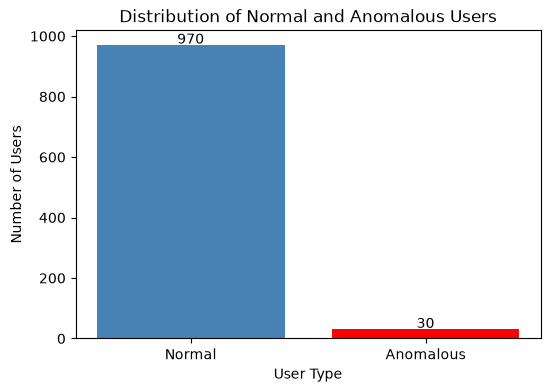

In [74]:
# Visualize anomaly detection results

counts = user_features['anomaly'].value_counts()

plt.figure(figsize=(6,4))
plt.bar(['Normal', 'Anomalous'], counts.sort_index(),
        color=['steelblue', 'red'])

plt.title('Distribution of Normal and Anomalous Users')
plt.xlabel('User Type')
plt.ylabel('Number of Users')

for i, v in enumerate(counts.sort_index()):
    plt.text(i, v + 5, str(v), ha='center')

plt.show()

In [76]:
# Save the trained model and deployment artifacts

# Save the trained Isolation Forest model
joblib.dump(
    model,
    'insider_threat_isolation_forest.pkl'
)

# Save the feature schema used during training
feature_columns = [
    'logon_count',
    'unique_pcs',
    'after_hours_logons',
    'device_events',
    'device_unique_pcs',
    'after_hours_device',
    'file_events',
    'unique_file',
    'after_hours_file'
]

joblib.dump(
    feature_columns,
    'model_features.pkl'
)

# Export detected anomalous users
anomalous_users = user_features[
    user_features['anomaly'] == 1
]

anomalous_users.to_csv(
    'detected_anomalous_users.csv',
    index=True
)

print("Model saved: insider_threat_isolation_forest.pkl")
print("Feature schema saved: model_features.pkl")
print("Anomaly report saved: detected_anomalous_users.csv")

Model saved: insider_threat_isolation_forest.pkl
Feature schema saved: model_features.pkl
Anomaly report saved: detected_anomalous_users.csv
